In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", x_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


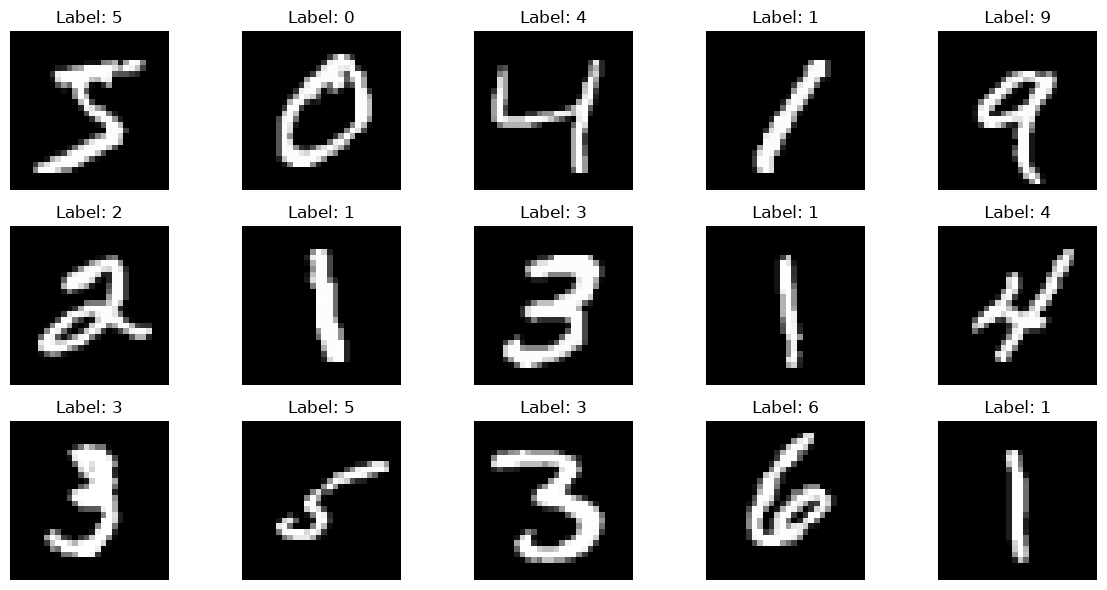

In [4]:
plt.figure(figsize=(12, 6))

for i in range(15):

    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
print("Minimum Pixel Value:", x_train.min())

print("Maximum Pixel Value:", x_train.max())

Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [6]:
print("First Image Matrix:")

print(x_train[0])

First Image Matrix:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 25

In [7]:
unique_digits = np.unique(y_train)

print("Unique Digit Classes:", unique_digits)

print("Total Classes:", len(unique_digits))

Unique Digit Classes: [0 1 2 3 4 5 6 7 8 9]
Total Classes: 10


In [8]:
print("Image Data Type:", x_train.dtype)

print("Label Data Type:", y_train.dtype)

Image Data Type: uint8
Label Data Type: uint8


In [9]:
print("First Image Shape:", x_train[0].shape)

print("Total Pixels:", x_train[0].size)

First Image Shape: (28, 28)
Total Pixels: 784


In [10]:
unique, counts = np.unique(y_train, return_counts=True)

for digit, count in zip(unique, counts):

    print(f"Digit {digit}: {count} images")

Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


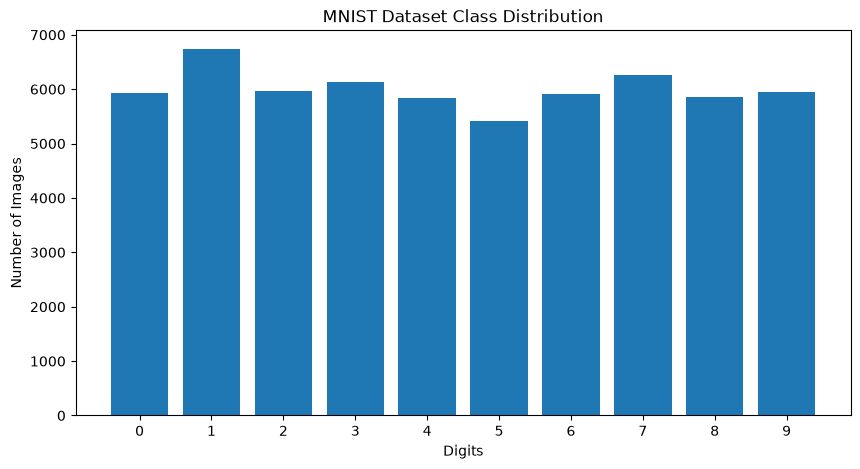

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(unique, counts)

plt.xlabel("Digits")

plt.ylabel("Number of Images")

plt.title("MNIST Dataset Class Distribution")

plt.xticks(range(10))

plt.show()

In [12]:
x_train = x_train / 255.0

x_test = x_test / 255.0

In [13]:
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Minimum: 0.0
Maximum: 1.0


In [14]:
x_train = x_train.astype('float32')

x_test = x_test.astype('float32')

In [15]:
print("Training Data Type:", x_train.dtype)

print("Testing Data Type:", x_test.dtype)

Training Data Type: float32
Testing Data Type: float32


In [16]:
print(x_train.shape)

(60000, 28, 28)


In [17]:
x_train = x_train.reshape(-1, 28, 28, 1)

x_test = x_test.reshape(-1, 28, 28, 1)

In [18]:
print("Training Shape:", x_train.shape)

print("Testing Shape:", x_test.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


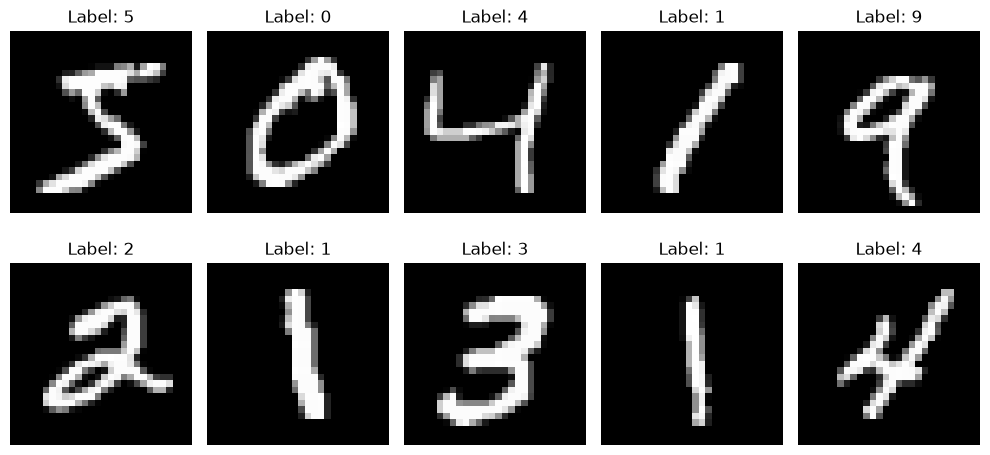

In [19]:
plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i].squeeze(), cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.tight_layout()

plt.show()

In [20]:
print("Training Shape:", x_train.shape)

print("Testing Shape:", x_test.shape)

print("Training Data Type:", x_train.dtype)

print("Testing Data Type:", x_test.dtype)

print("Minimum Pixel Value:", x_train.min())

print("Maximum Pixel Value:", x_train.max())

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)
Training Data Type: float32
Testing Data Type: float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [21]:
#CNN Model Building
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Create CNN model
model = Sequential()

# First convolution layer
model.add(Conv2D(
    32,
    (3, 3),
    activation='relu',
    input_shape=(28, 28, 1)
))

# First pooling layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second convolution layer
model.add(Conv2D(
    64,
    (3, 3),
    activation='relu'
))

# Second pooling layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten layer
model.add(Flatten())

# Fully connected layer
model.add(Dense(128, activation='relu'))

# Dropout
model.add(Dropout(0.3))

# Output layer
model.add(Dense(10, activation='softmax'))

# Display architecture
model.summary()

C:\Users\hp\Downloads\Desktop\projects\Handwritten_Digit_Recognition\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)       ┃ Output Shape  ┃ Param # ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ conv2d (Conv2D)    │ (None, 26,    │     320 │
│                    │ 26, 32)       │         │
├────────────────────┼───────────────┼─────────┤
│ max_pooling2d      │ (None, 13,    │       0 │
│ (MaxPooling2D)     │ 13, 32)       │         │
├────────────────────┼───────────────┼─────────┤
│ conv2d_1 (Conv2D)  │ (None, 11,    │  18,496 │
│                    │ 11, 64)       │         │
├────────────────────┼───────────────┼─────────┤
│ max_pooling2d_1    │ (None, 5, 5,  │       0 │
│ (MaxPooling2D)     │ 64)           │         │
├────────────────────┼───────────────┼─────────┤
│ flatten (Flatten)  │ (None, 1600)  │       0 │
├────────────────────┼───────────────┼─────────┤
│ dense (Dense)      │ (None, 128)   │ 204,928 │
├────────────────────┼───────────────┼─────────┤
│ dropout (Dropout)  │ (None, 128)   │       0 │
├────────────────────┼───────────────┼─────────┤
│ dense_1 (Dense)    │ (None, 10)    │   1,290 │
└────────────────────┴───────────────┴─────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compiled successfully!")

Model compiled successfully!


# CNN Model Training

In [23]:
# Train the CNN model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9364 - loss: 0.2084 - val_accuracy: 0.9840 - val_loss: 0.0530
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.9785 - loss: 0.0700 - val_accuracy: 0.9857 - val_loss: 0.0486
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9846 - loss: 0.0502 - val_accuracy: 0.9912 - val_loss: 0.0326
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9882 - loss: 0.0384 - val_accuracy: 0.9903 - val_loss: 0.0333
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9901 - loss: 0.0310 - val_accuracy: 0.9897 - val_loss: 0.0330


In [24]:
# Evaluate model using test dataset

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9897 - loss: 0.0332
Test Loss: 0.0332430936396122
Test Accuracy: 98.97000193595886 %


# Training Performance Visualization 

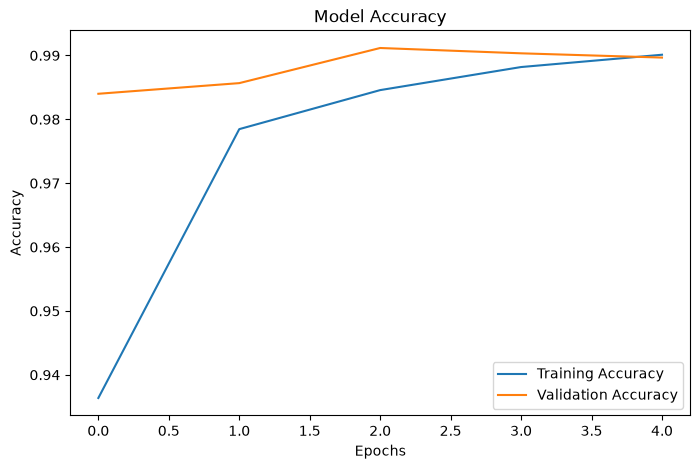

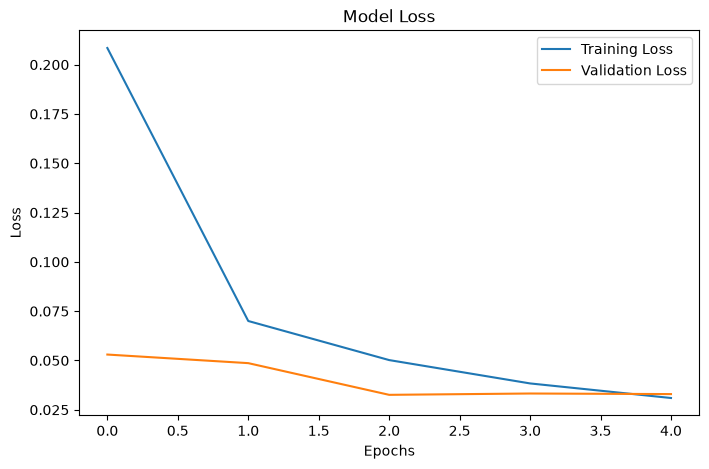

In [25]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [26]:
import os

os.makedirs("../models", exist_ok=True)

model.save("../models/digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


# Individual Digit Prediction

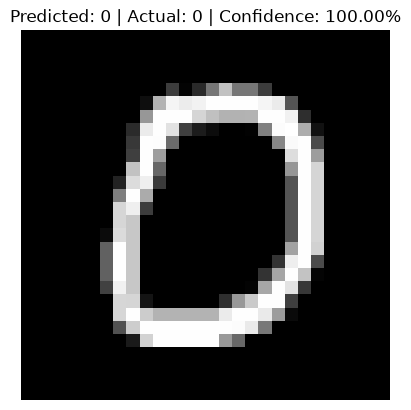

Predicted Digit: 0
Actual Digit: 0
Confidence: 99.99993 %


In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Select one image from test dataset
index = 10

image = x_test[index]

# Add batch dimension
image_input = np.expand_dims(image, axis=0)

# Predict
prediction = model.predict(image_input, verbose=0)

# Get predicted digit
predicted_digit = np.argmax(prediction)

# Get confidence
confidence = np.max(prediction) * 100

# Actual digit
actual_digit = y_test[index]

# Display image and prediction
plt.imshow(image.squeeze(), cmap='gray')
plt.title(
    f"Predicted: {predicted_digit} | "
    f"Actual: {actual_digit} | "
    f"Confidence: {confidence:.2f}%"
)
plt.axis('off')
plt.show()

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", actual_digit)
print("Confidence:", confidence, "%")

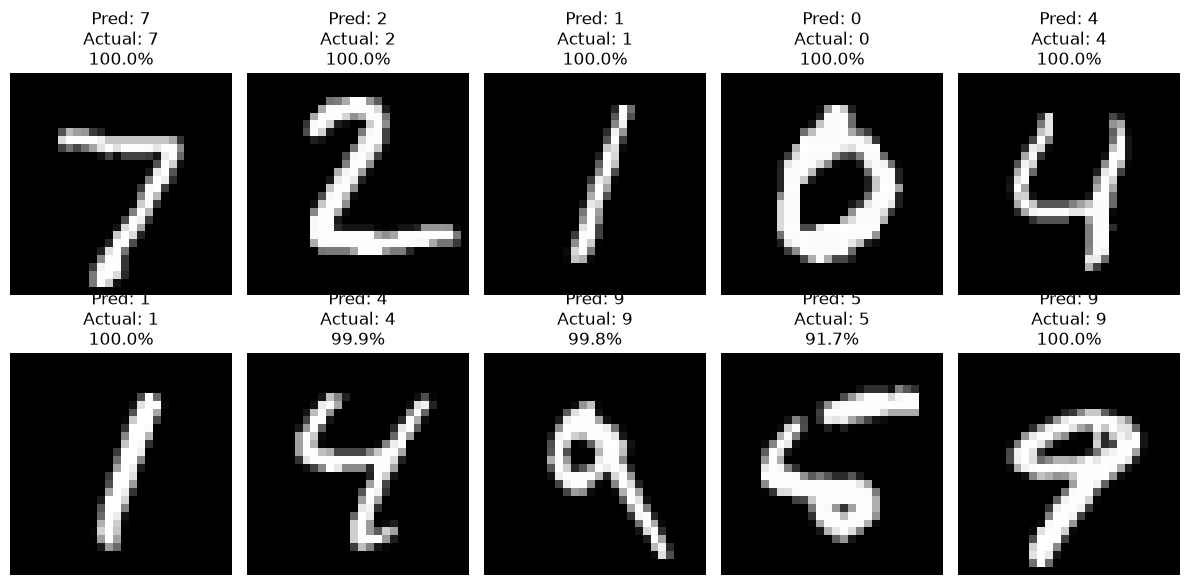

In [28]:
plt.figure(figsize=(12, 6))

for i in range(10):

    image = x_test[i]

    image_input = np.expand_dims(image, axis=0)

    prediction = model.predict(image_input, verbose=0)

    predicted_digit = np.argmax(prediction)

    actual_digit = y_test[i]

    confidence = np.max(prediction) * 100

    plt.subplot(2, 5, i + 1)

    plt.imshow(image.squeeze(), cmap='gray')

    plt.title(
        f"Pred: {predicted_digit}\n"
        f"Actual: {actual_digit}\n"
        f"{confidence:.1f}%"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

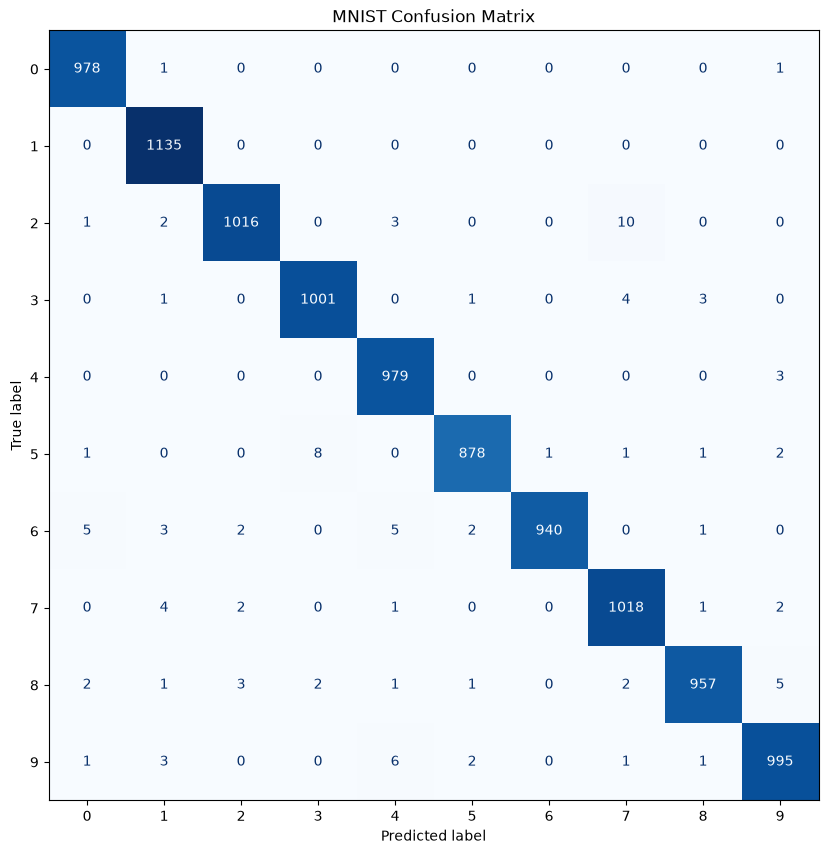

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Predict all test images
y_pred = model.predict(x_test, verbose=0)

# Convert probabilities into digit labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

# Set figure size
plt.figure(figsize=(10, 10))

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap='Blues', ax=plt.gca(), colorbar=False)

plt.title("MNIST Confusion Matrix")
plt.show()

# Create a temporary test cell in your notebook:

In [30]:
import sys

sys.path.append("..")

from preprocessing import preprocess_image

image = preprocess_image("../test_digit.JPEG")

print("Processed image shape:", image.shape)
print("Minimum pixel:", image.min())
print("Maximum pixel:", image.max())

Processed image shape: (1, 28, 28, 1)
Minimum pixel: 0.0
Maximum pixel: 1.0


# Testing CNN Model Accuracy

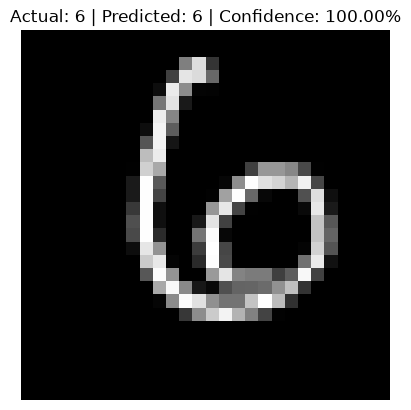

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Select an image from MNIST test dataset
index = 100

image = x_test[index]

# Predict
prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

# Get predicted digit
predicted_digit = np.argmax(prediction)

# Get actual digit
actual_digit = y_test[index]

# Confidence
confidence = np.max(prediction) * 100

# Display image
plt.imshow(image.squeeze(), cmap="gray")

plt.title(
    f"Actual: {actual_digit} | "
    f"Predicted: {predicted_digit} | "
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

In [32]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", test_accuracy * 100, "%")

Test Accuracy: 98.97000193595886 %


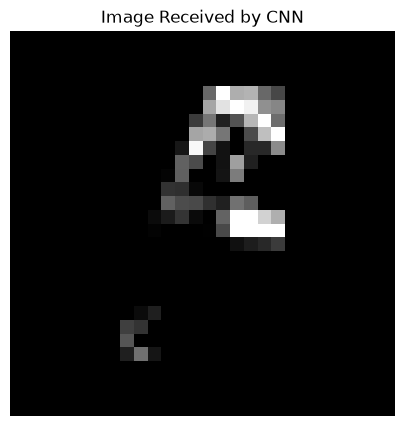

In [33]:
import sys
sys.path.append("..")

from preprocessing import preprocess_image

processed = preprocess_image("../test_digit.jpeg")

plt.figure(figsize=(5, 5))

plt.imshow(
    processed[0, :, :, 0],
    cmap="gray"
)

plt.title("Image Received by CNN")

plt.axis("off")
plt.show()

# 4. Test preprocessing again

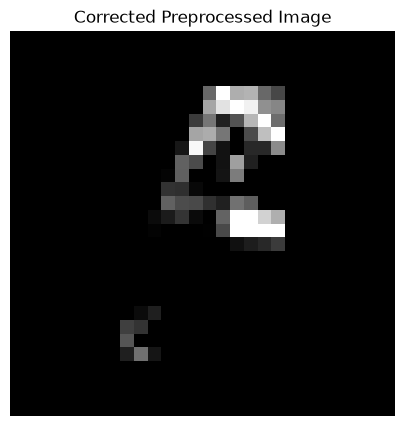

In [34]:
import sys
sys.path.append("..")

from preprocessing import preprocess_image

processed = preprocess_image("../test_digit.jpeg")

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(
    processed[0, :, :, 0],
    cmap="gray"
)

plt.title("Corrected Preprocessed Image")
plt.axis("off")
plt.show()

In [35]:
prediction = model.predict(processed, verbose=0)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")

Predicted Digit: 3
Confidence: 36.23 %


# Test both photographs in your notebook

In [ ]:
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")

import preprocessing

# Reload the latest preprocessing.py
importlib.reload(preprocessing)

# Test both images
images = ["../9.jpeg", "../test_digit.jpeg"]

for image_path in images:

    processed = preprocessing.preprocess_image(image_path)

    prediction = model.predict(processed, verbose=0)

    predicted_digit = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    plt.figure(figsize=(4, 4))

    plt.imshow(processed[0, :, :, 0], cmap="gray")

    plt.title(f"Predicted: {predicted_digit}")

    plt.axis("off")
    plt.show()

    print("Image:", image_path)
    print("Prediction:", predicted_digit)
    print("Confidence:", round(confidence, 2), "%")

In [37]:
import importlib
import preprocessing

importlib.reload(preprocessing)

<module 'preprocessing' from 'C:\\Users\\hp\\Downloads\\Desktop\\projects\\Handwritten_Digit_Recognition\\notebooks\\..\\preprocessing.py'>

Top 3 Predictions:
Digit: 1, Probability: 99.89%
Digit: 2, Probability: 0.05%
Digit: 8, Probability: 0.03%


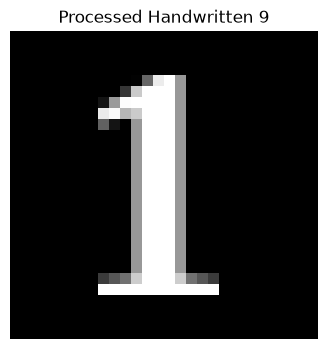

In [41]:
import importlib
import preprocessing
importlib.reload(preprocessing)

import numpy as np
import matplotlib.pyplot as plt

processed = preprocessing.preprocess_image("../1.jpg")

prediction = model.predict(processed, verbose=0)[0]

# Get top 3 predictions
top_indices = np.argsort(prediction)[-3:][::-1]

print("Top 3 Predictions:")

for digit in top_indices:
    print(
        f"Digit: {digit}, "
        f"Probability: {prediction[digit] * 100:.2f}%"
    )

# Visualize processed image
plt.figure(figsize=(4, 4))
plt.imshow(processed[0, :, :, 0], cmap="gray")
plt.title("Processed Handwritten 9")
plt.axis("off")
plt.show()

In [39]:
import importlib
import preprocessing

importlib.reload(preprocessing)

print("Latest preprocessing loaded!")

Latest preprocessing loaded!


# Real-World Handwritten Digit Recognition

Testing the trained CNN model using external handwritten digit photographs.

In [42]:
import os
import importlib
import numpy as np
import matplotlib.pyplot as plt

import preprocessing

# Load the latest preprocessing code
importlib.reload(preprocessing)

print("Preprocessing module loaded successfully!")

Preprocessing module loaded successfully!
